<a href="https://colab.research.google.com/github/Sha-119/IHL2/blob/main/start-here/NB00_start_here.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

# Start here: A Python warm-up

**Reinforcement Learning and Language Model Alignment (VTR UGE 21)**

**Prof. Dr. Utku Kose**

Full Professor, Department of Computer Engineering, Süleyman Demirel University, Isparta, Türkiye  
Founding Director, AI Application and Research Center (YAZEM), Süleyman Demirel University  
Head of the Computer Science Division, Department of Computer Engineering, Süleyman Demirel University  
Additional affiliations: University of North Dakota (USA), Universidad Panamericana (Mexico City, Mexico), Vel Tech University (Chennai, India)  
IEEE Senior Member, ACM Professional Member

[ORCID 0000-0002-9652-6415](https://orcid.org/0000-0002-9652-6415) | [utkukose.com](https://www.utkukose.com) | [github.com/utkukose](https://github.com/utkukose)

[utkukose@sdu.edu.tr](mailto:utkukose@sdu.edu.tr) | [utku.kose@und.edu](mailto:utku.kose@und.edu) | [ukose@up.edu.mx](mailto:ukose@up.edu.mx) | [utkukose@gmail.com](mailto:utkukose@gmail.com)

</div>

## How Colab works

A notebook is a sequence of cells. Text cells, like this one, explain. Code cells hold Python instructions: Click into a code cell and press Shift+Enter to run it. The output appears directly below. Run the cells in order from the top. If something goes wrong, the menu Runtime, then Restart session, starts again from a clean state. The first code cell below prints a line of text and the results of three calculations: `/` divides, and `**` raises to a power.

In [1]:
# Python practice: a small example for learning the language
print("Hello from the start-here notebook")
print(2 + 3, 10 / 4, 2 ** 8)

Hello from the start-here notebook
5 2.5 256


The next cell defines a small helper, `check`, that compares an answer with the expected value and prints feedback, and the cell after it keeps the expected values in the table `ANSWERS`, with its code hidden. Run both once; the exercises below use them. Each exercise starts with `None`, the Python value for nothing, in the place of the answer, and `check` reports it as not answered yet. An exercise calls `check` without the expected value, so that the answer does not stand next to it, and `check` looks the value up in `ANSWERS`. Reading the code of `check` is optional, since the sections below introduce most of its pieces, among them the default values in `expected=None` and `tol=1e-6`. One piece appears only here: The block under `try` compares the answer as a number, and if the answer is not a number, the block under `except` compares it as it is.

In [2]:
def check(name, value, expected=None, tol=1e-6):
    """Compares an answer with the expected value and prints immediate feedback. Without an expected value in the
    call, check takes the value and its tolerance from ANSWERS, the table of the next cell."""
    if expected is None:
        answer, tol = ANSWERS[name]
        expected = answer()
    if value is None:
        print(f"{name}: not answered yet. Replace None with your answer and run the cell again.")
        return False
    try:
        ok = abs(float(value) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    except (TypeError, ValueError):
        ok = value == expected
    print(f"{name}: " + ("correct." if ok else "not yet. Compare your steps with the lecture and try again."))
    return ok

In [6]:
#@title Expected answers of the exercises (run this cell; open it only after trying the exercises)
ANSWERS = {
    "Exercise 0.1": (lambda: 2.5, 1e-6),
    "Exercise 0.2": (lambda: 0.6, 1e-6),
    "Exercise 0.3": (lambda: 1.75, 1e-6),
    "Exercise 0.4": (lambda: round(float(running[-1]), 2), 1e-6),
}

## Variables and types

A variable is a name for a value, and `=` binds the value on its right to the name on its left. Numbers with a decimal point are floats, whole numbers are integers, text in quotation marks is a string, and `True` and `False` are booleans. `type` names the type of a value. The `f` before the quotation mark in the last line makes an f-string, which inserts the value of each name in braces into the text, and `:.1f` prints a number with one decimal.

In [3]:
# Python practice: a small example for learning the language
reward = 1.0
steps = 4
agent = "explorer"
done = False
print(type(reward), type(steps), type(agent), type(done))
print(f"The {agent} earned {reward:.1f} in {steps} steps.")

<class 'float'> <class 'int'> <class 'str'> <class 'bool'>
The explorer earned 1.0 in 4 steps.


**Exercise 0.1.** An agent receives the rewards 0, 0, 0 and 2.5 in four steps. Store the total in `total`.

In [7]:
total = 2.5   # your answer
check("Exercise 0.1", total)

Exercise 0.1: correct.


True

In [ ]:
#@title Reference solution (run this cell; open it only after trying)
total = 0 + 0 + 0 + 2.5
check("Exercise 0.1", total)

## Lists, loops and decisions

A list holds values in order. A `for` loop runs its indented block once for every element, and an `if` statement runs its block only when the condition is true. `else` runs its block when the condition is false. `enumerate(rewards)` hands the loop every element together with its position, counted from 0, and `for step, r in ...` gives the two the names `step` and `r`. `sum` adds the elements of a list, and `len` counts them.

In [8]:
# Python practice: a small example for learning the language
rewards = [0.0, 1.0, 0.0, 1.0, 1.0]
for step, r in enumerate(rewards):
    if r > 0:
        print(step, "win")
    else:
        print(step, "loss")
print("wins:", sum(rewards))

0 loss
1 win
2 loss
3 win
4 win
wins: 3.0


**Exercise 0.2.** Store the share of wins in `rewards`, the sum divided by the length, in `win_rate`.

In [9]:
win_rate = sum(rewards) / len(rewards)   # your answer
check("Exercise 0.2", win_rate)

Exercise 0.2: correct.


True

In [10]:
#@title Reference solution (run this cell; open it only after trying)
win_rate = sum(rewards) / len(rewards)
check("Exercise 0.2", win_rate)

Exercise 0.2: correct.


True

## Functions

`def` defines a reusable piece of code with parameters and a `return` value. The text in triple quotation marks describes the function. A parameter written with a value, such as `gamma=0.9`, has a default that applies when a call leaves it out. Inside `sum(...)`, the expression `r * gamma ** t for t, r in enumerate(rewards)` computes the discounted reward of every step, and `sum` adds them up. A loop written as an expression in this way is called a generator expression. `round(x, 3)` rounds to three decimals.

In [11]:
# Python practice: a small example for learning the language
def discounted_return(rewards, gamma=0.9):
    """Sum of rewards, each discounted by gamma per step."""
    return sum(r * gamma ** t for t, r in enumerate(rewards))

print(round(discounted_return([0, 0, 1]), 3))

0.81


**Exercise 0.3.** Use `discounted_return` to store the return of `[1, 1, 1]` with `gamma=0.5` in `g`.

In [13]:
g = discounted_return([1,1,1],gamma=0.5)   # your answer
check("Exercise 0.3", g)

Exercise 0.3: correct.


True

In [ ]:
#@title Reference solution (run this cell; open it only after trying)
g = discounted_return([1, 1, 1], gamma=0.5)
check("Exercise 0.3", g)

## Three libraries: NumPy, pandas and Matplotlib

`import` loads a library. NumPy computes with whole arrays at once, pandas holds tables with named columns, and Matplotlib draws plots. `import numpy as np` loads NumPy under the short name `np`. In the cell, `np.random.default_rng(0)` creates a random number generator, and the seed 0 makes it draw the same numbers in every run. `rng.random(200) < 0.3` draws 200 numbers between 0 and 1 and compares each with 0.3, which gives 200 booleans, each `True` with probability 0.3. `np.cumsum` adds the wins up pull by pull, and dividing by `np.arange(1, 201)`, the numbers from 1 to 200, turns the counts into the share of wins after every pull. Square brackets pick elements by their position, counted from 0: `running[[0, 9, 99, 199]]` picks four of them, and a negative position counts from the end. The curly braces build a dictionary, which maps keys to values, and `pd.DataFrame` turns it into a table with one column per key. `.round(3)` is a method, a function that belongs to a value and is written after a dot, and a semicolon puts two statements on one line.

   pull  estimate
0     1     0.000
1    10     0.300
2   100     0.250
3   200     0.265


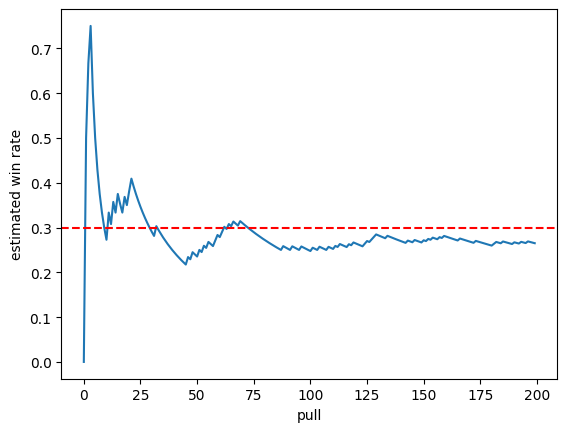

In [14]:
# Python practice: a small example for learning the language
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
wins = rng.random(200) < 0.3
running = np.cumsum(wins) / np.arange(1, 201)
print(pd.DataFrame({"pull": [1, 10, 100, 200], "estimate": running[[0, 9, 99, 199]].round(3)}))
plt.plot(running); plt.axhline(0.3, color="red", linestyle="--")
plt.xlabel("pull"); plt.ylabel("estimated win rate"); plt.show()

**Exercise 0.4.** Store the final estimate, the last element of `running`, rounded to two decimals, in `final_est`.

In [15]:
final_est = round(float(running[-1]),2)   # your answer
check("Exercise 0.4", final_est)

Exercise 0.4: correct.


True

In [ ]:
#@title Reference solution (run this cell; open it only after trying)
final_est = round(float(running[-1]), 2)
check("Exercise 0.4", final_est)

## Next step

The warm-up is complete. Continue with Day 1, whose Python step starts from exactly these ideas and applies them to a bandit.

---

<div align="center">

**Prof. Dr. Utku Kose**

Full Professor, Department of Computer Engineering, Süleyman Demirel University, Isparta, Türkiye  
Founding Director, AI Application and Research Center (YAZEM), Süleyman Demirel University  
Head of the Computer Science Division, Department of Computer Engineering, Süleyman Demirel University  
Additional affiliations: University of North Dakota (USA), Universidad Panamericana (Mexico City, Mexico), Vel Tech University (Chennai, India)  
IEEE Senior Member, ACM Professional Member

[ORCID 0000-0002-9652-6415](https://orcid.org/0000-0002-9652-6415) | [utkukose.com](https://www.utkukose.com) | [github.com/utkukose](https://github.com/utkukose)

[utkukose@sdu.edu.tr](mailto:utkukose@sdu.edu.tr) | [utku.kose@und.edu](mailto:utku.kose@und.edu) | [ukose@up.edu.mx](mailto:ukose@up.edu.mx) | [utkukose@gmail.com](mailto:utkukose@gmail.com)

</div>